# 01 — Learning Problem & Data Understanding (EDA)
**Tahap lifecycle:** [L] Learning Problem · **Minggu 2** · Bab 3.2, 4.1–4.4

**Judul kerja proyek:** Prediksi kemunculan *hotspot* (titik api) H+1 di lahan rawan karhutla Sumatra–Kalimantan dari data cuaca harian dan riwayat hotspot VIIRS.

> **Asumsi formulasi (mohon dikonfirmasi):** template laporan belum memuat judul/problem statement, sehingga formulasi di bawah disimpulkan dari dua dataset yang diunggah.
> SDG yang paling cocok: **SDG 13 – Penanganan Perubahan Iklim** (Target 13.1: memperkuat ketahanan & kapasitas adaptasi terhadap bencana terkait iklim).

| Komponen | Isi |
|---|---|
| **Target** | `fire_next_day` — biner: apakah ada ≥1 hotspot VIIRS (kebakaran vegetasi, confidence ≠ low) dalam radius **25 km** dari titik cuaca pada **hari berikutnya (t+1)**. Klasifikasi biner. |
| **Objective** | Meminimalkan *binary cross-entropy* (log-loss) dengan pembobotan kelas; metrik utama **PR-AUC (Average Precision)** dan **F1 kelas positif**, didukung ROC-AUC & recall. |
| **Data** | 6 titik cuaca × 2.871 hari (Open-Meteo) + 1,21 juta deteksi hotspot VIIRS NOAA-20 (2018-04 s.d. 2024-12). Data deret waktu spasial; **tidak i.i.d.** (autokorelasi temporal kuat) sehingga split dibuat kronologis. |

**Aturan penting notebook ini:** analisis hubungan fitur–target (EDA 3–6) **hanya memakai data train** (dan val untuk perbandingan tahunan). Data **test (tahun 2024) tidak dilihat**.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from matplotlib.patches import Circle
import prep

warnings.filterwarnings("ignore")
np.random.seed(prep.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

RAW = prep.find_raw_dir()
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
print("SEED =", prep.SEED, "| RADIUS_KM =", prep.RADIUS_KM, "| HORIZON =", prep.HORIZON_DAYS, "hari")

SEED = 42 | RADIUS_KM = 25 | HORIZON = 1 hari


## 4.1 Informasi Dataset

In [2]:
f_w, f_v = RAW / "data_cuaca_semua_lokasi.csv", RAW / "viirs-jpss1_2018_2025_Indonesia.csv"
w_raw = pd.read_csv(f_w)
v_raw = pd.read_csv(f_v)

info = pd.DataFrame({
    "dataset": ["Cuaca harian (Open-Meteo)", "Hotspot VIIRS NOAA-20 (NASA FIRMS)"],
    "file": [f_w.name, f_v.name],
    "baris": [len(w_raw), len(v_raw)],
    "kolom": [w_raw.shape[1], v_raw.shape[1]],
    "ukuran_MB": [round(f_w.stat().st_size / 1e6, 2), round(f_v.stat().st_size / 1e6, 2)],
    "format": ["CSV", "CSV"],
    "tipe_data": ["Tabular / time series spasial", "Tabular geospasial (event deteksi)"],
})
info

,dataset,file,baris,kolom,ukuran_MB,format,tipe_data
0,Cuaca harian (Open-Meteo),data_cuaca_semua_lokasi.csv,17226,11,2.43,CSV,Tabular / time series spasial
1,Hotspot VIIRS NOAA-20 (NASA FIRMS),viirs-jpss1_2018_2025_Indonesia.csv,1213145,16,103.80,CSV,Tabular geospasial (event deteksi)


In [3]:
print("== Cuaca ==");  print(w_raw.dtypes.to_string())
print("\n== VIIRS =="); print(v_raw.dtypes.to_string())

== Cuaca ==
latitude                        float64
longitude                       float64
date                                str
precipitation_sum               float64
temperature_2m_max              float64
et0_fao_evapotranspiration      float64
relative_humidity_2m_min        float64
wind_speed_10m_max              float64
vapour_pressure_deficit_max     float64
soil_moisture_0_to_7cm_mean     float64
soil_moisture_7_to_28cm_mean    float64

== VIIRS ==
latitude       float64
longitude      float64
bright_ti4     float64
scan           float64
track          float64
acq_date           str
acq_time         int64
satellite          str
instrument         str
confidence         str
version          int64
bright_ti5     float64
frp            float64
daynight           str
type             int64
source_year      int64


## 4.2 Deskripsi Fitur

In [4]:
def describe_cols(df):
    out = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unik": df.nunique(), "contoh": df.iloc[0]})
    num = df.select_dtypes("number")
    out.loc[num.columns, "min"] = num.min().round(3)
    out.loc[num.columns, "max"] = num.max().round(3)
    return out

print("=== CUACA ==="); display(describe_cols(w_raw))
print("=== VIIRS ==="); display(describe_cols(v_raw))

=== CUACA ===


,dtype,n_unik,contoh,min,max
latitude,float64,5,-3.268893,-3.761,-1.722
longitude,float64,6,105.266556,103.714,114.225
date,str,2871,2019-01-01 00:00:00+00:00,NaN,NaN
precipitation_sum,float64,1536,17.5,0.000,155.400
temperature_2m_max,float64,16796,29.44613,24.007,39.103
et0_fao_evapotranspiration,float64,17209,3.048608,0.521,6.663
relative_humidity_2m_min,float64,8942,75.65432,22.510,99.700
wind_speed_10m_max,float64,2617,15.408671,3.827,26.020
vapour_pressure_deficit_max,float64,8954,0.996875,0.009,5.040
soil_moisture_0_to_7cm_mean,float64,12694,0.418875,0.023,0.609


=== VIIRS ===


,dtype,n_unik,contoh,min,max
latitude,float64,687441,-8.20034,-10.976,5.854
longitude,float64,861020,119.0813,95.039,140.977
bright_ti4,float64,6439,317.37,207.930,367.000
scan,float64,49,0.42,0.320,0.800
track,float64,43,0.45,0.360,0.780
acq_date,str,2460,2018-04-01,NaN,NaN
acq_time,int64,550,1701,311.000,1955.000
satellite,str,1,N20,NaN,NaN
instrument,str,1,VIIRS,NaN,NaN
confidence,str,3,n,NaN,NaN


## 4.3 Kondisi Data

### Missing values, duplikat, cakupan waktu

In [5]:
rep = {}
rep["missing_cuaca"] = int(w_raw.isna().sum().sum())
rep["missing_viirs"] = int(v_raw.isna().sum().sum())
rep["duplikat_baris_cuaca"] = int(w_raw.duplicated().sum())
rep["duplikat_kunci_cuaca(lat,lon,date)"] = int(w_raw.duplicated(["latitude", "longitude", "date"]).sum())
rep["duplikat_baris_viirs"] = int(v_raw.duplicated().sum())
rep["duplikat_kunci_viirs(lat,lon,tanggal,jam)"] = int(v_raw.duplicated(["latitude", "longitude", "acq_date", "acq_time"]).sum())
print(pd.Series(rep).to_string())

w = prep.load_weather(f_w)
v = prep.load_viirs(f_v)
locs = prep.location_table(w)
days_per_loc = w.groupby("loc_id")["date"].agg(["min", "max", "count", "nunique"])
print("\nTitik cuaca:"); display(locs.merge(days_per_loc, on="loc_id"))
exp_days = (w["date"].max() - w["date"].min()).days + 1
print(f"Hari per lokasi diharapkan = {exp_days}, aktual = {days_per_loc['count'].unique()} -> tanpa hari hilang pada cuaca")
print(f"\nVIIRS: {v['acq_date'].min().date()} s.d. {v['acq_date'].max().date()} (nama file menyebut 2025, isi data berakhir 2024-12-31)")
print("Kolom konstan VIIRS:", [c for c in v.columns if v[c].nunique() == 1])
print("Hotspot per source_year:", v["source_year"].value_counts().sort_index().to_dict(), "(source_year = penanda berkas sumber, bukan tahun kejadian)")

missing_cuaca                                0
missing_viirs                                0
duplikat_baris_cuaca                         0
duplikat_kunci_cuaca(lat,lon,date)           0
duplikat_baris_viirs                         0
duplikat_kunci_viirs(lat,lon,tanggal,jam)    0



Titik cuaca:


,loc_id,latitude,longitude,min,max,count,nunique
0,L1,-1.722320,103.714287,2019-01-01,2026-11-10,2871,2871
1,L2,-3.268893,105.266556,2019-01-01,2026-11-10,2871,2871
2,L3,-3.760984,105.718925,2019-01-01,2026-11-10,2871,2871
3,L4,-1.722320,110.214294,2019-01-01,2026-11-10,2871,2871
4,L5,-2.776801,112.771080,2019-01-01,2026-11-10,2871,2871
5,L6,-2.284710,114.225235,2019-01-01,2026-11-10,2871,2871


Hari per lokasi diharapkan = 2871, aktual = [2871] -> tanpa hari hilang pada cuaca

VIIRS: 2018-04-01 s.d. 2024-12-31 (nama file menyebut 2025, isi data berakhir 2024-12-31)
Kolom konstan VIIRS: ['satellite', 'instrument', 'version']
Hotspot per source_year: {2018: 181069, 2019: 437645, 2020: 93213, 2021: 71063, 2022: 63803, 2023: 250312, 2024: 116040} (source_year = penanda berkas sumber, bukan tahun kejadian)


### Noise pada VIIRS: jenis sumber & tingkat kepercayaan

In [6]:
print(pd.crosstab(v["type"], v["confidence"], margins=True).rename(
    index={0: "0 vegetation fire", 1: "1 active volcano", 2: "2 other static land", 3: "3 offshore"}))
vf = prep.filter_viirs(v)
print(f"\nSetelah filter type==0 & confidence!='l': {len(vf):,} dari {len(v):,} deteksi ({len(vf)/len(v):.1%} dipertahankan)")
print("\nFRP (MW) - distribusi sangat miring ke kanan:")
print(v["frp"].describe(percentiles=[.5, .9, .99, .999]).round(2).to_string())

confidence               h      l        n      All
type                                               
0 vegetation fire    32765  82965  1005956  1121686
1 active volcano       600    485    21455    22540
2 other static land    476   1469    60388    62333
3 offshore             498    318     5770     6586
All                  34339  85237  1093569  1213145

Setelah filter type==0 & confidence!='l': 1,038,721 dari 1,213,145 deteksi (85.6% dipertahankan)

FRP (MW) - distribusi sangat miring ke kanan:
count    1213145.00
mean           7.73
std           14.16
min            0.00
50%            4.57
90%           15.31
99%           56.92
99.9%        169.75
max         1840.60


### Hari tanpa data satelit (gap) — mencegah 'nol palsu' pada label

In [7]:
gaps = prep.gap_days(v, v["acq_date"].min(), v["acq_date"].max())
print("Hari dengan 0 hotspot di SELURUH Indonesia:", [d.strftime("%Y-%m-%d") for d in gaps])
print("Median hotspot nasional per hari:", int(v.groupby("acq_date").size().median()))

Hari dengan 0 hotspot di SELURUH Indonesia: ['2023-07-19', '2023-07-20', '2023-07-21', '2023-07-22', '2023-09-30', '2024-02-04', '2024-02-05']
Median hotspot nasional per hari: 159


### Outlier pada fitur cuaca (aturan IQR 1,5×)

In [8]:
rows = []
for c in prep.RAW_WEATHER_COLS:
    q1, q3 = w[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((w[c] < lo) | (w[c] > hi)).sum())
    rows.append([c, round(w[c].skew(), 2), n_out, round(100 * n_out / len(w), 2), round(w[c].min(), 3), round(w[c].max(), 3)])
out_tbl = pd.DataFrame(rows, columns=["fitur", "skewness", "n_outlier_IQR", "%_outlier", "min", "max"])
display(out_tbl)
print("RH min 0-100%:", w["relative_humidity_2m_min"].between(0, 100).all(),
      "| presipitasi >= 0:", (w["precipitation_sum"] >= 0).all(),
      "| soil moisture 0-1:", w[["soil_moisture_0_to_7cm_mean", "soil_moisture_7_to_28cm_mean"]].apply(lambda s: s.between(0, 1).all()).all())

,fitur,skewness,n_outlier_IQR,%_outlier,min,max
0,precipitation_sum,2.34,615,3.57,0.000,155.400
1,temperature_2m_max,0.09,574,3.33,24.007,39.103
2,et0_fao_evapotranspiration,-0.16,202,1.17,0.521,6.663
3,relative_humidity_2m_min,-0.49,484,2.81,22.510,99.700
4,wind_speed_10m_max,0.56,137,0.80,3.827,26.020
5,vapour_pressure_deficit_max,1.05,652,3.78,0.009,5.040
6,soil_moisture_0_to_7cm_mean,-0.40,31,0.18,0.023,0.609
7,soil_moisture_7_to_28cm_mean,-0.31,0,0.00,0.056,0.610


RH min 0-100%: True | presipitasi >= 0: True | soil moisture 0-1: True


### Membangun tabel berlabel (pipeline `src/prep.py`) & imbalance kelas

In [9]:
df, binfo = prep.build_dataset(RAW)
feat_all = prep.RAW_WEATHER_COLS + prep.WEATHER_ENGINEERED + prep.HOTSPOT_HISTORY + prep.SEASONAL
lab = df.dropna(subset=["fire_next_day"] + feat_all).copy()
lab["fire_next_day"] = lab["fire_next_day"].astype(int)
print("Baris berlabel & lengkap:", len(lab), "| per split:", lab["split"].value_counts().to_dict())

# --- Mulai di sini EDA hanya memakai train (+val untuk perbandingan antar-tahun). TEST TIDAK DISENTUH. ---
tr  = lab[lab["split"] == "train"].copy()
trv = lab[lab["split"].isin(["train", "val"])].copy()
vc = tr["fire_next_day"].value_counts().sort_index()
print(f"\nImbalance (train): negatif={vc[0]}, positif={vc[1]}, rasio {vc[0]/vc[1]:.1f}:1, positif = {vc[1]/len(tr):.1%}")

Baris berlabel & lengkap: 12912 | per split: {'train': 8586, 'test': 2178, 'val': 2148}

Imbalance (train): negatif=7728, positif=858, rasio 9.0:1, positif = 10.0%


## 4.4 Exploratory Data Analysis
Semua gambar disimpan ke `reports/figures/`.

### Visualisasi 1 — Musiman & variasi antar-tahun hotspot

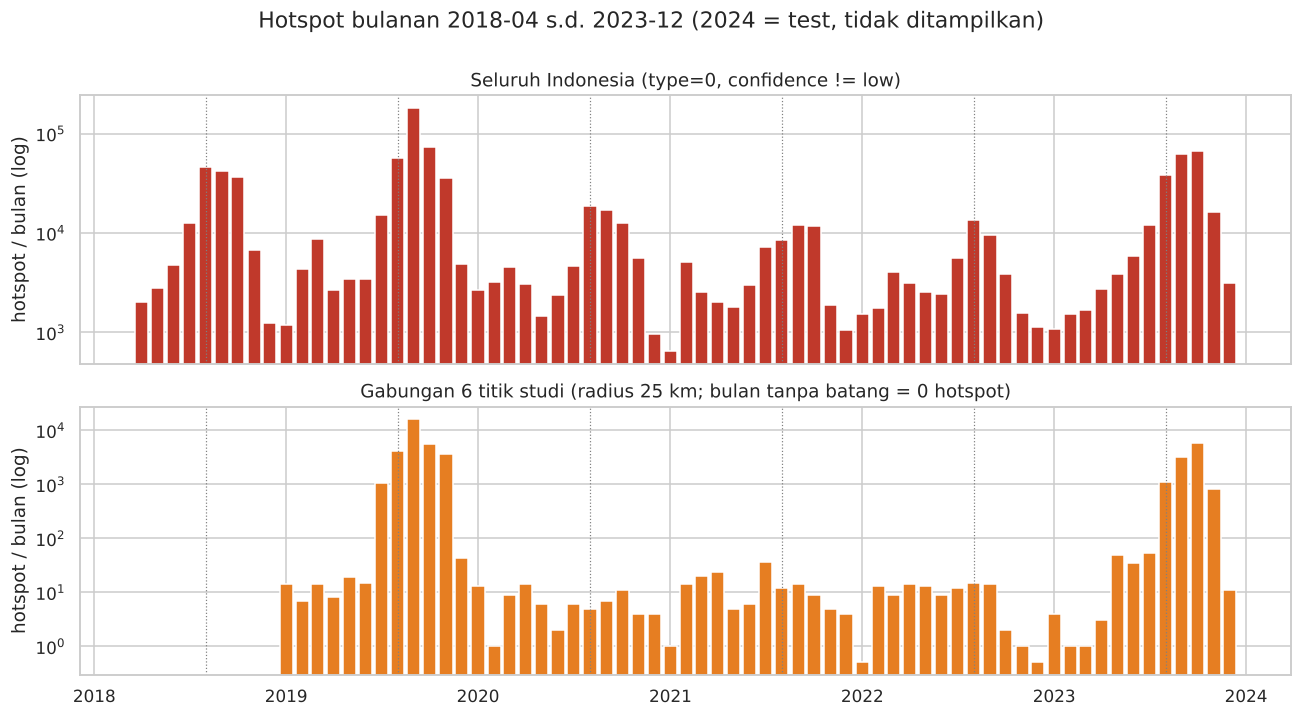

acq_date
2018    155469
2019    390952
2020     76570
2021     57589
2022     50337
2023    214626


In [10]:
vf_trv = vf[vf["acq_date"] <= prep.VAL_END]
m_nat = vf_trv.groupby(vf_trv["acq_date"].dt.to_period("M")).size().to_timestamp()
loc_m = (df[df["date"] <= prep.VAL_END].groupby(df["date"].dt.to_period("M"))["hs_count"].sum()).to_timestamp()

fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].bar(m_nat.index, m_nat.values, width=25, color="#c0392b"); ax[0].set_yscale("log")
ax[0].set_ylabel("hotspot / bulan (log)"); ax[0].set_title("Seluruh Indonesia (type=0, confidence != low)")
ax[1].bar(loc_m.index, loc_m.values.clip(min=0.5), width=25, color="#e67e22"); ax[1].set_yscale("log")
ax[1].set_ylabel("hotspot / bulan (log)"); ax[1].set_title("Gabungan 6 titik studi (radius 25 km; bulan tanpa batang = 0 hotspot)")
for a in ax:
    for y in range(2018, 2024): a.axvline(pd.Timestamp(f"{y}-08-01"), color="grey", ls=":", lw=.8)
fig.suptitle("Hotspot bulanan 2018-04 s.d. 2023-12 (2024 = test, tidak ditampilkan)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "fig01_hotspot_bulanan.png"); plt.show()
print(m_nat.groupby(m_nat.index.year).sum().to_string())

**Insight:**  
Hotspot sangat musiman: puncaknya selalu Agustus–Oktober (musim kemarau), dan nyaris nol pada Desember–Juni. Intensitas antar-tahun berbeda drastis: 2019 (≈391 ribu deteksi nasional) dan 2023 (≈215 ribu) jauh di atas 2020–2022 (≈50–77 ribu per tahun, tahun basah/La Niña). Di 6 titik studi pola yang sama muncul: kebakaran hanya besar pada 2019 dan 2023. Konsekuensi: (1) fitur kalender/musiman (`doy_sin`, `doy_cos`) layak dibuat; (2) proporsi kelas positif sangat bergantung pada tahun sehingga **ada pergeseran distribusi antar-tahun** — split acak akan menutupi masalah ini, sehingga dipakai split kronologis.

### Visualisasi 2 — Sebaran spasial hotspot & posisi titik studi

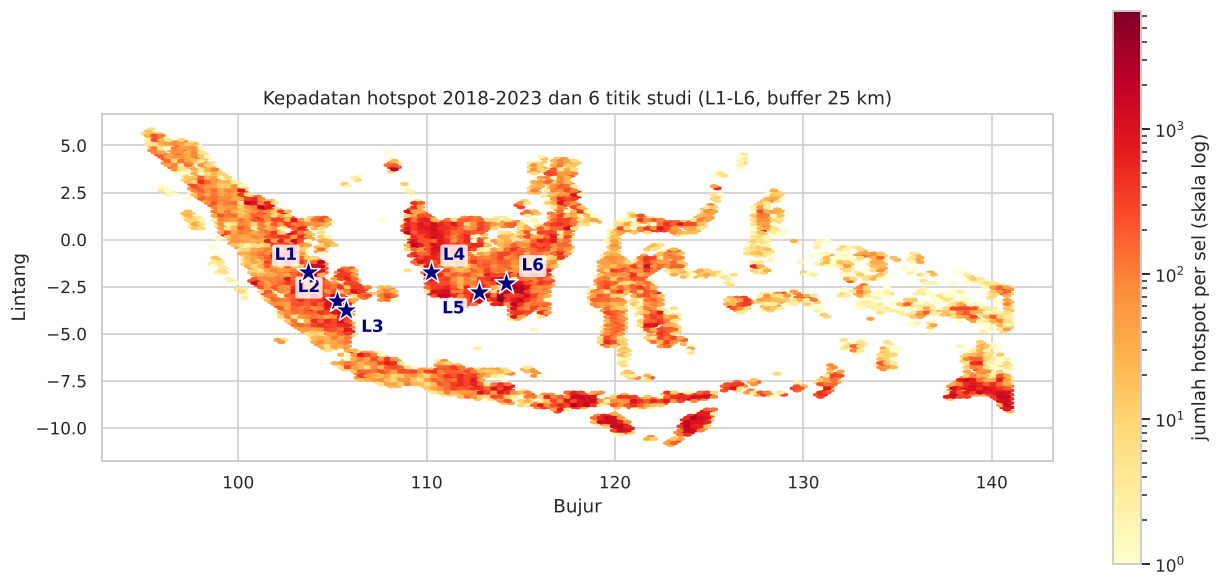

loc_id  latitude  longitude
    L1    -1.722    103.714
    L2    -3.269    105.267
    L3    -3.761    105.719
    L4    -1.722    110.214
    L5    -2.777    112.771
    L6    -2.285    114.225


In [11]:
fig, ax = plt.subplots(figsize=(12, 5.5))
hb = ax.hexbin(vf_trv["longitude"], vf_trv["latitude"], gridsize=130, bins="log", cmap="YlOrRd", mincnt=1)
plt.colorbar(hb, ax=ax, label="jumlah hotspot per sel (skala log)")
ax.scatter(locs["longitude"], locs["latitude"], marker="*", s=260, c="navy", edgecolor="white", zorder=5)
off = {"L1": (-22, 8), "L2": (-26, 6), "L3": (10, -14), "L4": (8, 8), "L5": (-24, -14), "L6": (10, 8)}
for _, r in locs.iterrows():
    ax.annotate(r["loc_id"], (r["longitude"], r["latitude"]), xytext=off[r["loc_id"]], textcoords="offset points",
                fontsize=11, fontweight="bold", color="navy",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.8))
ax.set_xlabel("Bujur"); ax.set_ylabel("Lintang"); ax.set_aspect("equal")
ax.set_title("Kepadatan hotspot 2018-2023 dan 6 titik studi (L1-L6, buffer 25 km)")
fig.tight_layout(); fig.savefig(FIG / "fig02_peta_hotspot_titik.png"); plt.show()
print(locs.round(3).to_string(index=False))

**Insight:**  
Keenam titik berada di pulau Sumatra bagian selatan (L1–L3) dan Kalimantan (L4–L6) — dua kawasan dengan konsentrasi hotspot tertinggi di Indonesia pada peta (sel merah tua), sesuai dengan kawasan lahan gambut/lahan kering rawan karhutla. L2 dan L3 hanya berjarak ≈74 km sehingga buffer 25 km tidak saling tumpang tindih (label tiap titik independen). Model yang dilatih pada data ini hanya mewakili 6 lokasi tersebut; generalisasi ke lokasi lain **tidak** diuji (keterbatasan yang dicatat).

### Visualisasi 3 — Peluang hotspot besok menurut bulan & lokasi (train)

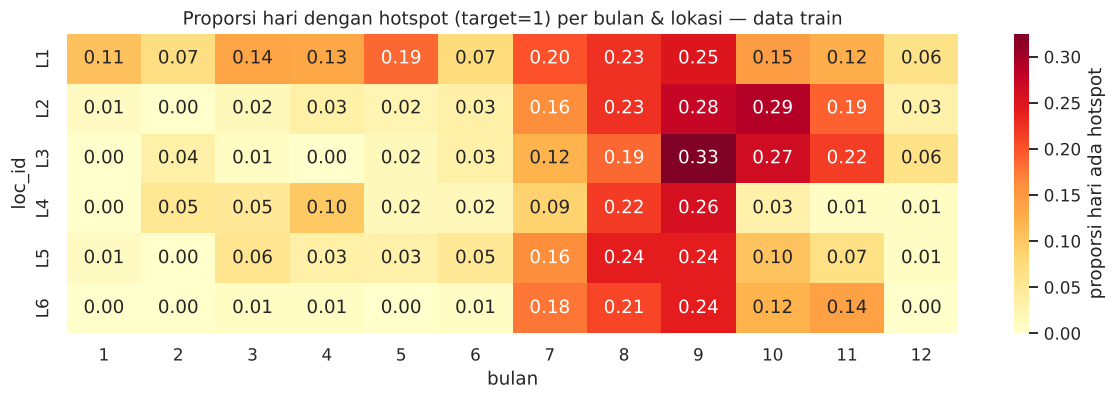

Rata-rata per bulan: {1: 0.021, 2: 0.027, 3: 0.046, 4: 0.051, 5: 0.046, 6: 0.036, 7: 0.152, 8: 0.218, 9: 0.265, 10: 0.16, 11: 0.125, 12: 0.03}


In [12]:
piv = (tr.assign(bulan=tr["target_date"].dt.month)
         .pivot_table(index="loc_id", columns="bulan", values="fire_next_day", aggfunc="mean"))
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "proporsi hari ada hotspot"}, ax=ax)
ax.set_title("Proporsi hari dengan hotspot (target=1) per bulan & lokasi — data train")
fig.tight_layout(); fig.savefig(FIG / "fig03_heatmap_bulan_lokasi.png"); plt.show()
print("Rata-rata per bulan:", piv.mean().round(3).to_dict())

**Insight:**  
Ada musim api yang jelas: rata-rata proporsi hari ber-hotspot naik dari ≈2–5% (Jan–Jun) menjadi ≈15% (Jul), 22% (Agu), 27% (Sep), 16% (Okt), 13% (Nov), lalu turun lagi di Des. Puncak Sumatra Selatan (L2, L3) bergeser ke September–Oktober (hingga 0,29–0,33), sedangkan Kalimantan (L4–L6) memuncak Agustus–September. L1 (Jambi) berbeda: api muncul sepanjang tahun (6–25%) sehingga relatif sulit dibedakan dari musimnya saja. Catatan: angka ini dihitung dari data train yang didominasi tahun 2019, sehingga level absolutnya bias ke tahun api besar.

### Visualisasi 4 — Fitur kunci menurut kelas target (train)

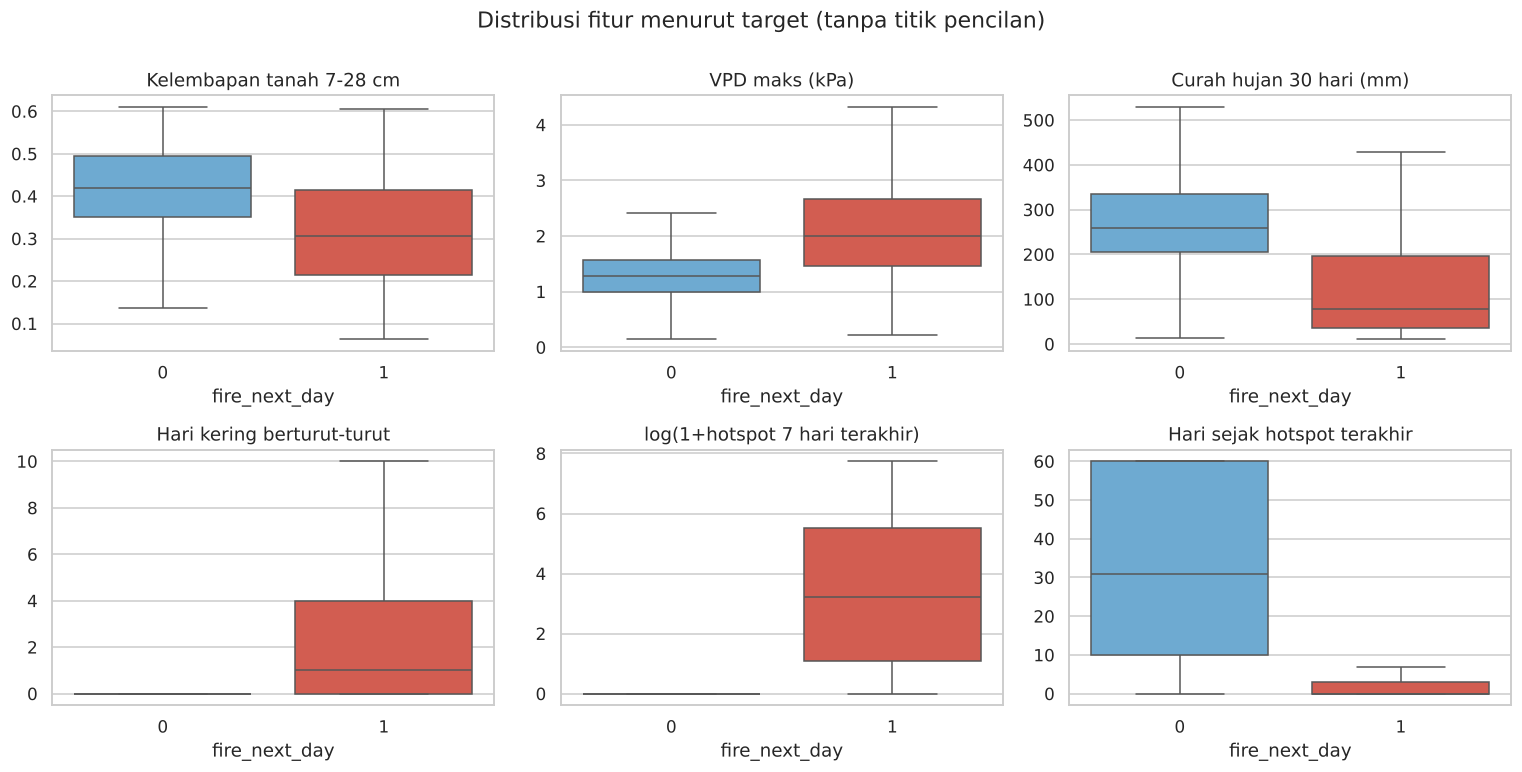

fire_next_day                       0       1
soil_moisture_7_to_28cm_mean    0.419   0.306
vapour_pressure_deficit_max     1.278   2.006
precip_sum_30d                260.000  77.500
dry_days_consec                 0.000   1.000
log1p_hs_count_7d               0.000   3.219
hs_days_since_last             31.000   0.000


In [13]:
tr["log1p_hs_count_7d"] = np.log1p(tr["hs_count_7d"])
cols = [("soil_moisture_7_to_28cm_mean", "Kelembapan tanah 7-28 cm"),
        ("vapour_pressure_deficit_max", "VPD maks (kPa)"),
        ("precip_sum_30d", "Curah hujan 30 hari (mm)"),
        ("dry_days_consec", "Hari kering berturut-turut"),
        ("log1p_hs_count_7d", "log(1+hotspot 7 hari terakhir)"),
        ("hs_days_since_last", "Hari sejak hotspot terakhir")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (c, t) in zip(axes.ravel(), cols):
    sns.boxplot(data=tr, x="fire_next_day", y=c, hue="fire_next_day", legend=False, ax=ax,
                palette=["#5dade2", "#e74c3c"], showfliers=False)
    ax.set_title(t); ax.set_xlabel("fire_next_day"); ax.set_ylabel("")
fig.suptitle("Distribusi fitur menurut target (tanpa titik pencilan)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "fig04_boxplot_fitur_vs_target.png"); plt.show()
print(tr.groupby("fire_next_day")[[c for c, _ in cols]].median().round(3).T.to_string())

**Insight:**  
Hari sebelum ada hotspot (kelas 1) memiliki kelembapan tanah 7–28 cm lebih rendah (median 0,31 vs 0,42), VPD lebih tinggi (2,01 vs 1,28 kPa), hujan 30 hari jauh lebih sedikit (median 77,5 vs 260 mm) dan lebih banyak hari kering berturut-turut. Fitur riwayat hotspot paling tajam memisahkan kelas: median hotspot 7 hari terakhir ≈ 0 untuk kelas 0 tetapi ≈ 24 untuk kelas 1, dan hari sejak hotspot terakhir median 31 vs 0. Artinya prediksi sebagian besar berasal dari **persistensi** (api hari ini → api besok) ditambah sinyal kekeringan; Minggu 3 perlu ablation (dengan vs tanpa fitur riwayat) agar kontribusi cuaca sendiri terukur.

### Visualisasi 5 — Korelasi antar fitur (Spearman, train)

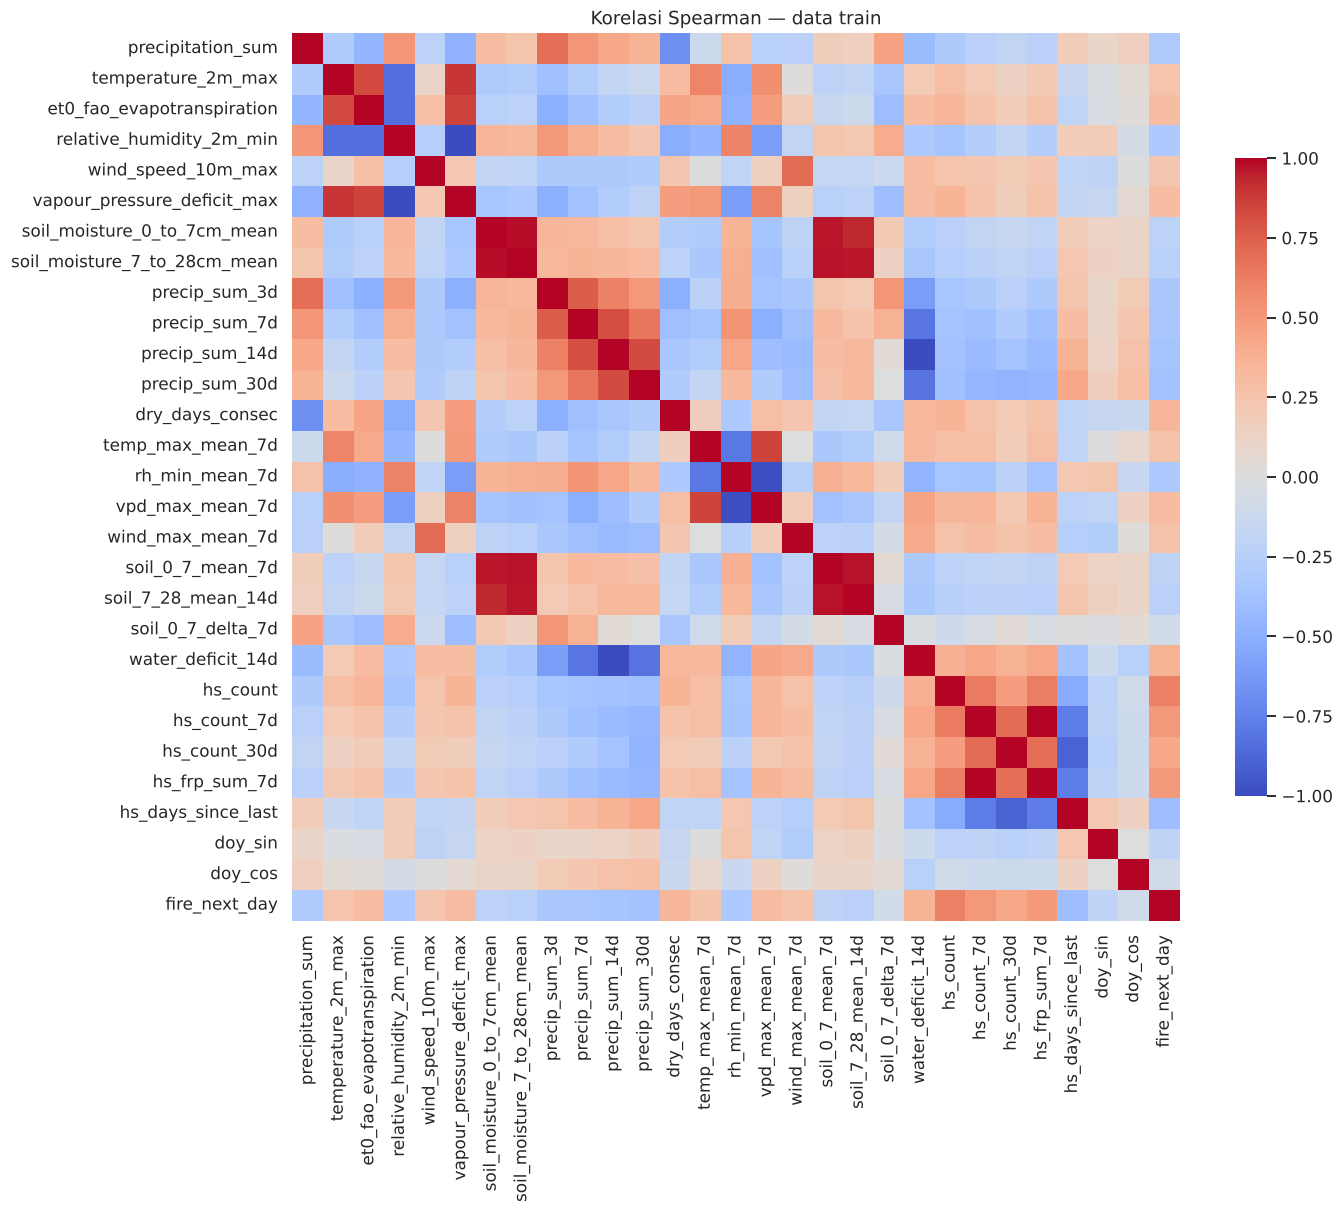

Korelasi dengan target:
hs_count                        0.614
hs_count_7d                     0.505
hs_frp_sum_7d                   0.499
hs_count_30d                    0.428
water_deficit_14d               0.361
dry_days_consec                 0.350
vpd_max_mean_7d                 0.312
vapour_pressure_deficit_max     0.312
et0_fao_evapotranspiration      0.302
temp_max_mean_7d                0.263
wind_max_mean_7d                0.261
temperature_2m_max              0.251
wind_speed_10m_max              0.236
soil_0_7_delta_7d              -0.079
doy_cos                        -0.092
doy_sin                        -0.208
soil_0_7_mean_7d               -0.212
soil_moisture_0_to_7cm_mean    -0.219
soil_7_28_mean_14d             -0.241
soil_moisture_7_to_28cm_mean   -0.245
precipitation_sum              -0.303
relative_humidity_2m_min       -0.319
rh_min_mean_7d                 -0.319
precip_sum_3d                  -0.321
precip_sum_7d                  -0.344
precip_sum_14d            

[None, None, None, None, None, None]

In [14]:
corr = tr[feat_all + ["fire_next_day"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Korelasi Spearman — data train")
fig.tight_layout(); fig.savefig(FIG / "fig05_korelasi_spearman.png"); plt.show()
print("Korelasi dengan target:"); print(corr["fire_next_day"].drop("fire_next_day").sort_values(ascending=False).round(3).to_string())
hi = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(feat_all) for b in feat_all[i+1:] if abs(corr.loc[a, b]) > 0.97]
print("\nPasangan fitur dengan |rho| > 0.97:"); [print(" ", h) for h in sorted(hi, key=lambda x: -abs(x[2]))]

**Insight:**  
Korelasi tertinggi dengan target: `hs_count` (0,61), `hs_count_7d` (0,51), `hs_days_since_last` (−0,40), `precip_sum_30d` (−0,37), `water_deficit_14d` (0,36). Banyak fitur redundan: RH minimum vs VPD (|ρ| = 0,99), curah hujan 14 hari vs defisit air (0,996), hotspot 7 hari vs FRP 7 hari (0,996), dan kelembapan tanah dua lapisan (0,98). Multikolinearitas ini tidak merusak model berbasis pohon tetapi membuat koefisien regresi logistik tidak stabil dan membuang kapasitas MLP; karena itu dilakukan seleksi fitur berbasis korelasi (ambang |ρ| > 0,97) **yang dihitung hanya pada train** di notebook 02.

### Visualisasi 6 — Distribusi kelas per tahun & per lokasi (pergeseran distribusi)

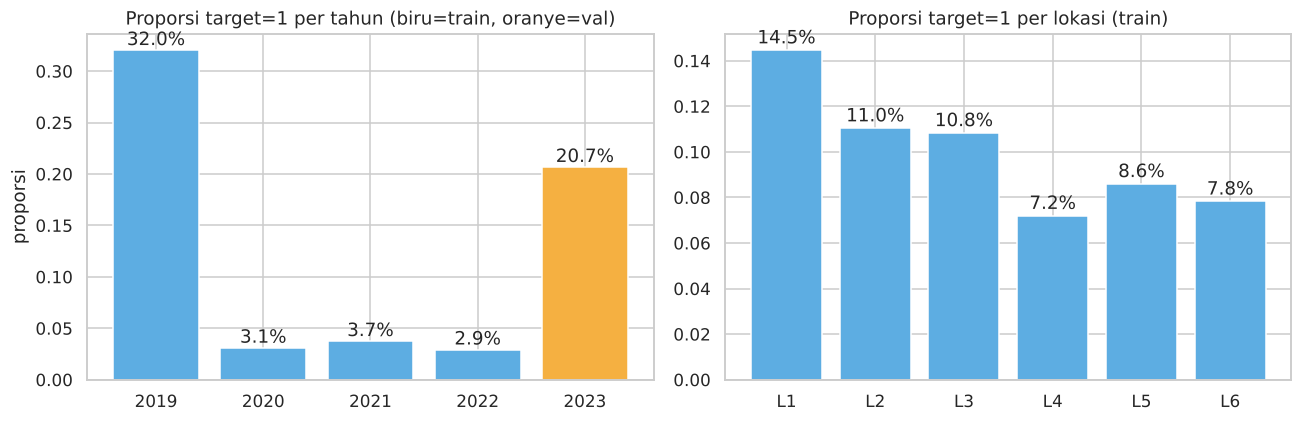

              mean  size
target_date             
2019         0.320  2010
2020         0.031  2196
2021         0.037  2190
2022         0.029  2190
2023         0.207  2148
         mean  size
loc_id             
L1      0.145  1431
L2      0.110  1431
L3      0.108  1431
L4      0.072  1431
L5      0.086  1431
L6      0.078  1431


In [15]:
by_year = trv.groupby(trv["target_date"].dt.year)["fire_next_day"].agg(["mean", "size"])
by_loc = tr.groupby("loc_id")["fire_next_day"].agg(["mean", "size"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#5dade2" if y <= 2022 else "#f5b041" for y in by_year.index]
ax[0].bar(by_year.index.astype(str), by_year["mean"], color=colors)
for i, (y, r) in enumerate(by_year.iterrows()): ax[0].text(i, r["mean"] + .005, f"{r['mean']:.1%}", ha="center")
ax[0].set_title("Proporsi target=1 per tahun (biru=train, oranye=val)"); ax[0].set_ylabel("proporsi")
ax[1].bar(by_loc.index, by_loc["mean"], color="#5dade2")
for i, (l, r) in enumerate(by_loc.iterrows()): ax[1].text(i, r["mean"] + .003, f"{r['mean']:.1%}", ha="center")
ax[1].set_title("Proporsi target=1 per lokasi (train)")
fig.tight_layout(); fig.savefig(FIG / "fig06_kelas_per_tahun_lokasi.png"); plt.show()
print(by_year.round(3).to_string()); print(by_loc.round(3).to_string())

**Insight:**  
Proporsi target=1 pada train hanya 10,0% (rasio ≈ 9:1), tetapi sangat berbeda antar tahun: 32,0% (2019), 3,1% / 3,7% / 2,9% (2020–2022), dan 20,7% pada validasi 2023. Antar lokasi 7–15% (L1 tertinggi). Jadi (a) kelas positif minoritas → metrik utama PR-AUC/F1, bukan accuracy; (b) distribusi train ≠ validasi: validasi memiliki lebih banyak kelas positif, sehingga skor validasi tidak bisa dibaca sebagai prediksi langsung performa test dan perlu kehati-hatian saat memilih threshold.

## Ringkasan temuan → keputusan untuk `02_data_preparation`
| Temuan EDA/kondisi data | Keputusan di notebook 02 |
|---|---|
| Tidak ada missing value & duplikat pada kedua dataset | Cukup verifikasi dengan `assert`; tidak perlu imputasi |
| VIIRS mengandung sumber non-kebakaran-vegetasi (type 1–3) dan deteksi confidence *low* (14,4% dibuang) | Filter `type==0` dan `confidence != 'l'` sebelum membuat label |
| 7 hari tanpa hotspot di seluruh Indonesia (indikasi data satelit hilang) | Dianggap *missing*, bukan 0; baris dengan target/hari-t pada hari tsb dibuang |
| Data VIIRS berakhir 2024-12-31 (bukan 2025); cuaca berlanjut sampai 2026-11-10 | Label hanya untuk periode tumpang-tindih 2019-01-01 s.d. 2024-12-31; cuaca setelahnya tidak dipakai |
| Curah hujan & FRP miring kanan; outlier cuaca bersifat fisik (hujan lebat, VPD tinggi) | Outlier **tidak dihapus**; `log1p` pada presipitasi, hitungan hotspot, FRP |
| Target tidak seimbang (≈9:1 di train) | Class weight dari train saja; metrik PR-AUC/F1 |
| Musiman & pergeseran antar tahun kuat; deret waktu tidak i.i.d. | Split kronologis (train 2019–2022, val 2023, test 2024); fitur `doy_sin/cos` |
| Multikolinearitas tinggi (|ρ| > 0,97) | Seleksi fitur berbasis korelasi, hanya di train |
| Riwayat hotspot sangat dominan | Dipisah sebagai grup fitur `hs_*` agar dapat di-ablation pada Minggu 3 |